### Problem statement
System: In -> A -> B -> C

<br>

**In $\rightarrow$ A:** Transform Qubit Readout data. Messages arrive with fixed mean arrival rate $\lambda$. Infinite queue if stage A blocked.

**A:** Read message. Processing time $\mathrm{Uniform}(1.5, 2.2)\mu s$.

**A $\rightarrow$ B:** FIFO buffer. Capacity = 100. If full A stops

**B:** Log-Normal distribution processing time $\mu = 0.5 , \sigma ^2 = 0.5$

**B $\rightarrow$ C:** FIFO buffer. Capacity = 25. If full B stops

**C:** Constant time of $1.5\mu s$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Num Qubits: 4625
Mean qubit times: 4565.207327534275
Latency from enter A: 194.12886706099684
A utilisation:  0.9460585998506115
B utilisation:  0.998826599842295
C utilisation:  0.6938048998904817


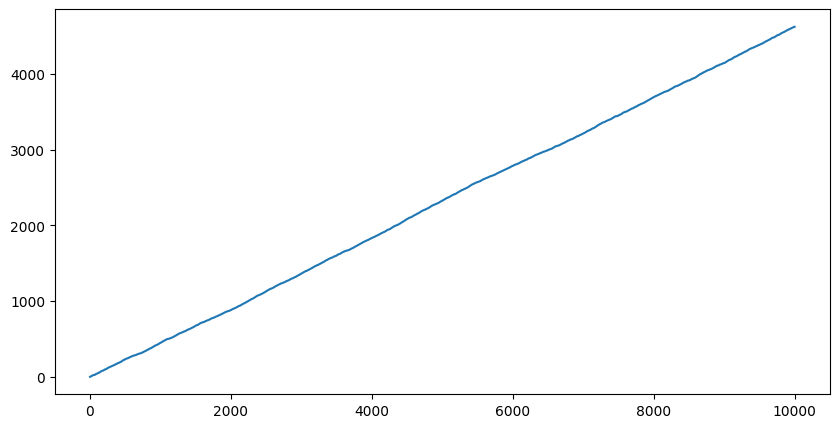

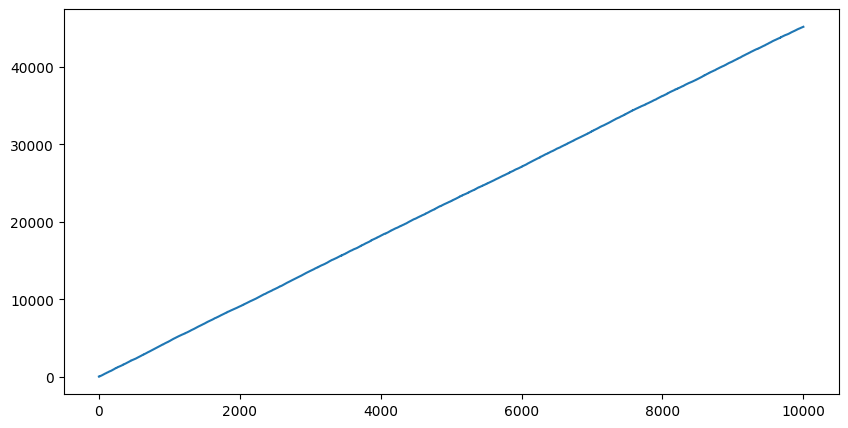

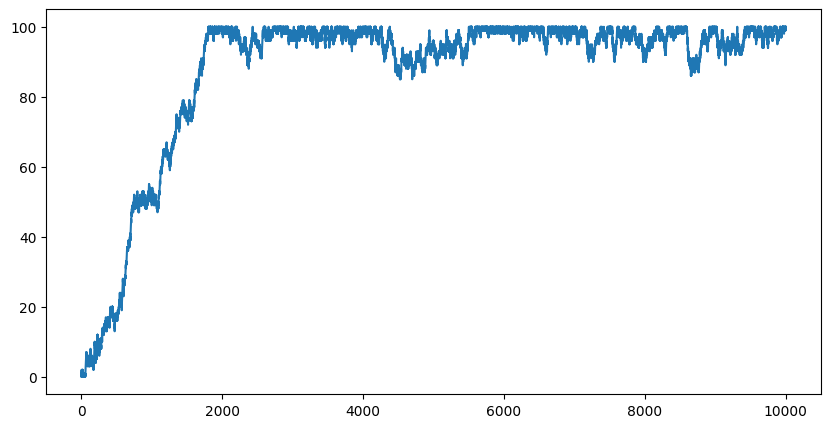

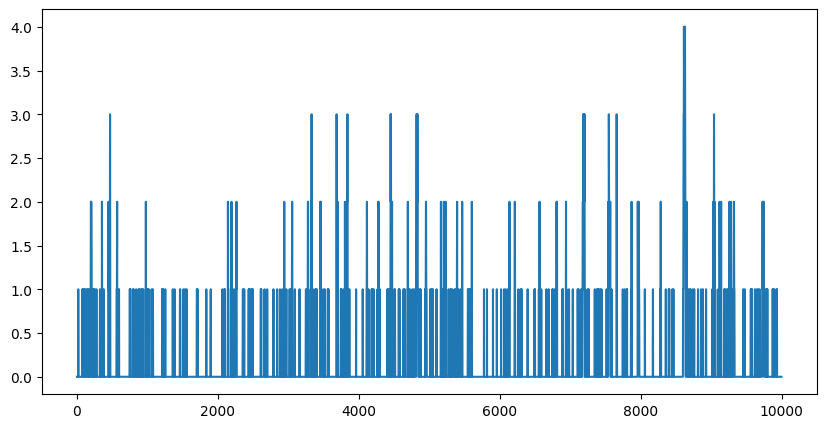

In [ ]:
class Queue:
    def __init__(self, max_length):
        self.length = 0
        self.max_length = max_length

class Source:
    def __init__(self, lam):
        self.lam = lam

    def next_arrival(self):
        return np.random.exponential(scale=self.lam)

def run_sim(lam, max_time):

    ts = 0.001
    max_time = max_time

    b_queue = Queue(100)
    c_queue = Queue(25)
    a_queue = Queue(1e8)
        
    source = Source(lam)

    # Initialise variables
    time = 0.0
    a_time = 0.0
    b_time = 0.0
    c_time = 0.0

    a_stopped = False
    b_stopped = False

    qubits_in_a = 0
    qubits_in_b = 0
    qubits_in_c = 0

    qubit_enter_a_times = []

    next_a_arrival = source.next_arrival()

    # To gather statistics
    callbacks = {
        'a_queue_lengths': [],
        'b_queue_lengths': [],
        'c_queue_lengths': [],
        'a_time_on': 0.0,
        'b_time_on': 0.0,
        'c_time_on': 0.0,
        'qubit_in_times': [],
        'latency_from_a': 0,
        'qubit_out_times': [],
        'final_queue_lengths': [0, 0, 0],
        'total_time': 0,
        'component_utilisation': {},
        'mean_time_in_system': 0,
        'times_in_system': []
    }

    while time < max_time:
        
        # Qubit enters the system. Enters queue into A
        if next_a_arrival < ts:
            a_queue.length += 1

            next_a_arrival = source.next_arrival()

            callbacks['qubit_in_times'] += [time]
            callbacks['a_queue_lengths'] += [(a_queue.length, time)]

        # Qubit enters A. Sample from Uniform distribution to determine time spent in A
        if (a_queue.length > 0) and (a_time < ts) and (not a_stopped):
            
            # Handles time at > 3 decimal places (np.random generated floats with higher percision. Some residual left when a_time < ts)
            extra_time = a_time

            # Use to ensure qubit doesn't exit A when initial qubit enters
            qubits_in_a += 1

            a_queue.length -= 1

            a_time = np.random.random() + 1.5

            # Gather statistics
            callbacks['a_time_on'] += (a_time - extra_time)
            qubit_enter_a_times += [time]
            callbacks['a_queue_lengths'] += [(a_queue.length, time)]

            # Add to B que ue if not at capacity. 
            if (b_queue.length < b_queue.max_length) and (qubits_in_a > 1):
                b_queue.length += 1
                callbacks['b_queue_lengths'] += [(b_queue.length, time)]

                # If this causes B queue to reach capacity pause system A, preventing other qubits entering
                if b_queue.length == b_queue.max_length:
                    a_stopped = True


        if (b_queue.length > 0) and (b_time < ts) and (not b_stopped):

            # Unpause system A when queue space frees up
            a_stopped = False

            # Handles time at >3 decimal places
            extra_time = b_time

            # Same as A
            qubits_in_b += 1

            b_queue.length -= 1

            b_time = np.random.lognormal(mean=0.5, sigma=np.sqrt(0.5))

            callbacks['b_queue_lengths'] += [(b_queue.length, time)]
            callbacks['b_time_on'] += (b_time - extra_time)

            # Same as A
            if (c_queue.length < c_queue.max_length) and (qubits_in_b > 1):
                c_queue.length += 1
                # callbacks['c_queue_lengths'] += [(c_queue.length/, time)]

                # Same as A
                if c_queue.length == c_queue.max_length:
                    b_stopped = True


        if (c_queue.length > 0) and (c_time < ts):
            b_stopped = False

            qubits_in_c += 1
            c_queue.length -= 1

            c_time = 1.5
            
            callbacks['c_queue_lengths'] += [(c_queue.length, time)]
            callbacks['c_time_on'] += 1.5

            if qubits_in_c > 1:
                # Deterministic time: 1.5 micros. No residuals
                callbacks['qubit_out_times'] += [time]

        # Step time
        time += ts
        next_a_arrival -= ts
        if a_time > 0:
            a_time -= ts
        if b_time > 0:
            b_time -= ts
        if c_time > 0:
            c_time -= ts

    # Calculate and store statistics
    callbacks['final_queue_lengths'][0] = a_queue.length
    callbacks['final_queue_lengths'][1] = b_queue.length
    callbacks['final_queue_lengths'][2] = c_queue.length

    callbacks['a_time_on'] -= a_time
    callbacks['b_time_on'] -= b_time
    callbacks['c_time_on'] -= c_time

    callbacks['decoding_rate'] = len(callbacks['qubit_out_times'])/time

    callbacks['component_utilisation']['a'] = callbacks['a_time_on']/time
    callbacks['component_utilisation']['b'] = callbacks['b_time_on']/time
    callbacks['component_utilisation']['c'] = callbacks['c_time_on']/time

    callbacks['times_in_system'] = [(callbacks['qubit_out_times'][i] - callbacks['qubit_in_times'][i]) for i in range(len(callbacks['qubit_out_times']))]
    callbacks['mean_time_in_system'] = np.mean(callbacks['times_in_system'])
    callbacks['latency_from_a'] = np.mean([(callbacks['qubit_out_times'][i] - qubit_enter_a_times[i]) for i in range(len(callbacks['qubit_out_times']))])


    return callbacks

callbacks = run_sim(0.2, 10000)

print('Num Qubits:', len(callbacks['qubit_out_times']))

print('Mean qubit times:', callbacks['mean_time_in_system'])
print('Latency from enter A:', callbacks['latency_from_a'])

print('A utilisation: ', callbacks['component_utilisation']['a'])
print('B utilisation: ', callbacks['component_utilisation']['b'])
print('C utilisation: ', callbacks['component_utilisation']['c'])


fig = plt.figure(figsize = (10, 5))
plt.plot(callbacks['qubit_out_times'], range(1, len(callbacks['qubit_out_times'])+1))
plt.show()

y, x = zip(*callbacks['a_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['b_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['c_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()


## Comments

1. B seems to be bottleneck. Everything downstream is clear
2. Maybe worth doing a plot explainig how B maxing out affects A
3. Final throughput/sec should be ~1/lambda until bottleneck appears. Plot of 1/lambda vs throughput/sec
4. May be worth doing mean time from when they enter A as opposed to when they enter the queue

In [206]:
len(callbacks['qubit_in_times']), len(callbacks['qubit_out_times']), callbacks['final_queue_lengths'][0], callbacks['final_queue_lengths'][1], callbacks['final_queue_lengths'][2]

(5020, 4663, 256, 98, 0)

In [ ]:
test_no = 10
lams = [0.5, 1.0, 1.5, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 3.0, 3.5, 4.0, 4.5]
latency_from_a_means = []
total_latency_means = []
decoding_rate = []

a_utilisation_means = []
b_utilisation_means = []
c_utilisation_means = []

for lam in lams:

    latencies_from_a = []
    total_latencies = []
    decoding = []

    a_utilisation = []
    b_utilisation = []
    c_utilisation = []

    for _ in range(test_no):
        results = run_sim(lam, 10000)

        # Gather results for given value of lambda
        latencies_from_a.append(results['latency_from_a'])
        total_latencies.append(results['mean_time_in_system'])
        decoding.append(results['decoding_rate'])
        a_utilisation.append(results['component_utilisation']['a'])
        b_utilisation.append(results['component_utilisation']['b'])
        c_utilisation.append(results['component_utilisation']['c'])

    # Calculate means for each run
    latency_from_a_means.append(np.mean(latencies_from_a))
    total_latency_means.append(np.mean(total_latencies))
    decoding_rate.append(np.mean(decoding))
    a_utilisation_means.append(np.mean(a_utilisation))
    b_utilisation_means.append(np.mean(b_utilisation))
    c_utilisation_means.append(np.mean(c_utilisation))

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, latency_from_a_means)
plt.title('Latency from entering A')
plt.xlabel('lambda')
plt.ylabel('latency (microseconds)')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, total_latency_means)
plt.title('Total Latency')
plt.xlabel('lambda')
plt.ylabel('latency (microseconds)')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, decoding_rate)
plt.title('Decoding Rate')
plt.xlabel('lambda')
plt.ylabel('Qubits/microsecond')
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, a_utilisation_means, label='A')
plt.plot(lams, b_utilisation_means, label='B')
plt.plot(lams, c_utilisation_means, label='C')
plt.title('Component Utilisation')
plt.xlabel('lambda')
plt.ylabel('Utilisation')
plt.legend()
plt.show()


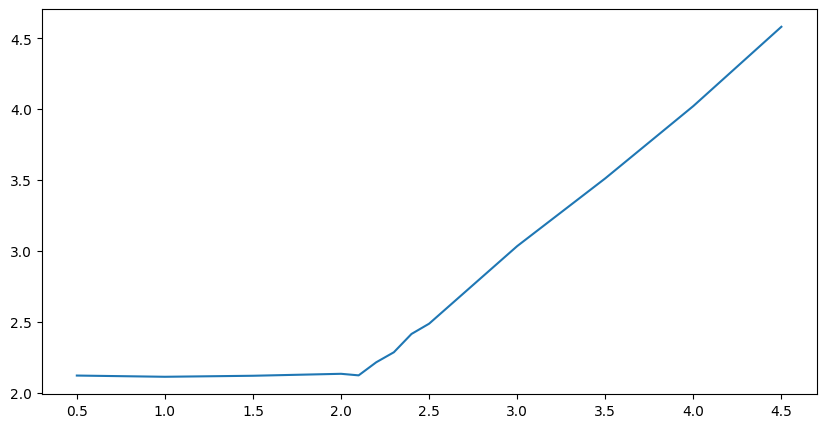

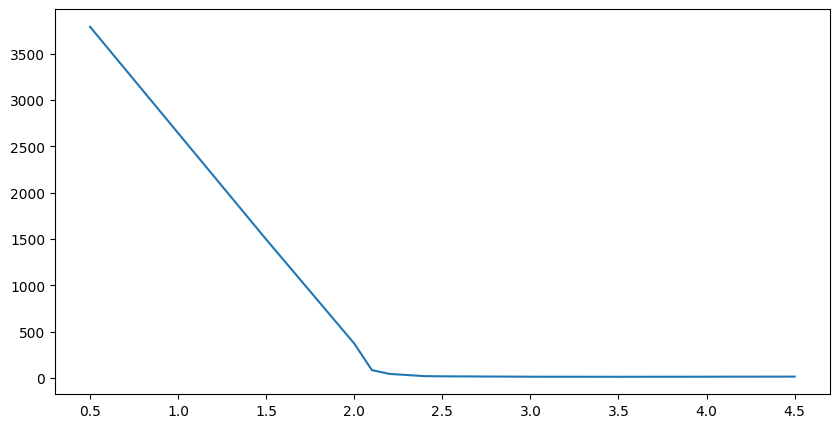

In [231]:
fig = plt.figure(figsize = (10, 5))
plt.plot(lams, [1/x for x in decoding_rate])
plt.show()

fig = plt.figure(figsize = (10, 5))
plt.plot(lams, total_latency_means)
plt.show()

### Method
Use Discrete Event Simulation to model the system. 